# 05 · Explaining the real-data alerts (Milestone 4) — 5 YEARS (2021–2025)

Notebook 04b produced a ranked list of vessel-weeks to look at first. This notebook answers **why** each one was flagged, and checks whether those explanations can be trusted.

**For each top alert**
1. **What drove the score?** *Integrated Gradients* traces the score back to the inputs. They are grouped into readable feature groups (fishing outside its flag state's waters, protected-area fishing, encounters, AIS gaps, …) and three roles: the vessel **this week**, its **own past weeks**, and **other vessels** linked to it in the graph.
2. **Did its history matter?** Each past week is removed from the graph, then all of them, and the vessel is re-scored.
3. **Did other vessels matter?** Encounter and co-location links are removed, one at a time and all together, and the vessel is re-scored. Every link is tested exactly.
4. **What would change the score?** Counterfactuals: *"had it not fished in foreign waters this week, the priority would fall from 0.54 to 0.09"*.
5. **A plain-language reason card** is saved as JSON with the caveat.

**Can the explanations be trusted?**
- **Completeness:** the attributions must add up to the score.
- **Deletion fidelity:** removing the 5 most important inputs must lower the score far more than removing 5 random ones.
- **Sparsity:** how few inputs carry most of the explanation.
- **Stability:** the same alerts are explained with 3 independently trained models, and the explanations should agree.

**Global view:** which information the graph model and gradient boosting rely on across all test weeks, measured by permutation importance.

**Runtime:** use a **T4 GPU**, about 10–15 min. The data is read from your Drive, as in 04b; no token or download is needed.

> ⚠️ An explanation describes **the model's** reasoning, not the vessel's intent. Priority is for investigation only. It is never evidence of illegality.

In [1]:
# ---- Setup: works in Google Colab (CPU is enough) and locally --------------------
import os, sys, subprocess, pathlib, zipfile, glob
IN_COLAB = "google.colab" in sys.modules
REPO_URL = ""          # optional: URL of your GitHub copy of this repository
USE_DRIVE = False      # True = keep project + outputs on Google Drive (restart-safe)

if IN_COLAB:
    PROJECT_DIR = pathlib.Path("/content/india-fishing-gnn")
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = pathlib.Path("/content/drive/MyDrive/india-fishing-gnn")
    if not (PROJECT_DIR / "src").exists():
        if REPO_URL:
            subprocess.run(["git", "clone", "-q", REPO_URL, str(PROJECT_DIR)], check=True)
        else:
            # accepts renamed downloads such as "india-fishing-gnn (1).zip"
            zips = sorted(glob.glob("/content/india-fishing-gnn*.zip"), key=os.path.getmtime)
            if not zips:
                from google.colab import files
                print("Project zip not found - choose india-fishing-gnn.zip from your computer:")
                uploaded = files.upload()   # file picker appears below this cell
                zips = [os.path.abspath(n) for n in uploaded if n.endswith(".zip")]
            if not zips:
                raise FileNotFoundError("No project zip uploaded.")
            print("Extracting", zips[-1])
            zipfile.ZipFile(zips[-1]).extractall(PROJECT_DIR.parent)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(PROJECT_DIR / "requirements-colab.txt")], check=True)
else:
    PROJECT_DIR = pathlib.Path.cwd()
    while not (PROJECT_DIR / "src").exists() and PROJECT_DIR != PROJECT_DIR.parent:
        PROJECT_DIR = PROJECT_DIR.parent

os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR))
print("Project directory:", PROJECT_DIR, "| Colab:", IN_COLAB)

Project zip not found - choose india-fishing-gnn.zip from your computer:


Saving india-fishing-gnn_5yr.zip to india-fishing-gnn_5yr.zip
Extracting /content/india-fishing-gnn_5yr.zip
Project directory: /content/india-fishing-gnn | Colab: True


## 0 · Mount Drive and find the saved real data

In [2]:
from pathlib import Path
DRIVE_DATA = Path("/content/drive/MyDrive/india-fishing-gnn-data")
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
from src.real_model import find_real_dir
REAL_DIR = find_real_dir()
OUT = (DRIVE_DATA / "outputs_05") if IN_COLAB else (PROJECT_DIR / "outputs" / "real_05")
(OUT / "figures").mkdir(parents=True, exist_ok=True)
FIG = OUT / "figures"
print("real data:", REAL_DIR, "| results ->", OUT)

Mounted at /content/drive
real data: /content/drive/MyDrive/india-fishing-gnn-data/real_gfw | results -> /content/drive/MyDrive/india-fishing-gnn-data/outputs_05


## 1 · Settings

In [3]:
import json, time, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 200)
from src import real_model as rm
from src import explainers as xp
from src import visualization as viz

FAST_MODE = False                 # True = 1 seed (no stability check), 10 alerts
N_ALERTS = 10 if FAST_MODE else 20
N_FIGURES = 3                     # detailed explanation figures for the top alerts
PROV = json.loads((REAL_DIR / "provenance.json").read_text()) if (REAL_DIR / "provenance.json").exists() else {}
CFG = rm.RealConfig(seeds=(0,) if FAST_MODE else (0, 1, 2), study_start=PROV.get("start", "2021-01-01"))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| seeds:", CFG.seeds, "| alerts to explain:", N_ALERTS)
print(rm.REAL_MODEL_CAVEAT)

device: cuda | seeds: (0, 1, 2) | alerts to explain: 20
REAL DATA (Global Fishing Watch). Scores are an investigation PRIORITY derived from forecasts of next-week activity patterns. They are not evidence of illegal fishing; every alert needs human verification. Vessel identities are anonymised.


## 2 · Rebuild the real vessel-week graph (same steps as 04b, about 1–2 min)

In [4]:
ev_raw, _, _ = rm.load_real(REAL_DIR)
ev, rep = rm.clean_events(ev_raw, CFG)
keep, vclass, _ = rm.select_vessels(ev, CFG)
ev = ev[ev.vessel_id.isin(keep)].reset_index(drop=True)
nodes = rm.weekly_table(ev, vclass, CFG)
G = rm.build_real_graph(nodes, ev, CFG)
split, gtrain = rm.time_split(nodes, CFG)
tasks = rm.active_tasks(G, split, CFG)
display(rm.graph_summary(G).rename("count").to_frame())
print("forecast tasks:", tasks)

,count
nodes (vessel-weeks),250831
vessels,14198
fishing-vessel nodes,248879
nodes with a next week (have targets),124658
temporal edges,519041
encounter edges (directed),24414
co-location edges (directed),1048834
node features,41


forecast tasks: ['encounter', 'loitering', 'fishing_in_mpa', 'fishing_outside_flag_eez']


## 3 · Train the full temporal graph model (one per seed) and gradient boosting

In [5]:
models = {}
for seed in CFG.seeds:
    r = rm.train_real(G, split, gtrain, CFG, seed, DEVICE, "full", tasks)
    models[seed] = r
    print(f"seed {seed}: val macro PR-AUC {r['best_val']:.4f} ({r['epochs']} epochs, {r['seconds']:.0f}s)")
best_seed = max(models, key=lambda k: models[k]["best_val"])
R = models[best_seed]
Z, stats = rm.standardize(G["X_raw"], split == "train")
Pc = rm.calibrate(R["P"], G, split, tasks)
priority = rm.investigation_priority(Pc, tasks, CFG.priority_weights)
pred = {"P": R["P"], "Pcal": Pc, "priority": priority, "tasks": tasks}
alerts = rm.alert_table(G, pred, split, top=N_ALERTS, weights=CFG.priority_weights)
display(alerts[["rank", "vessel_id", "week", "lat", "lon", "priority", "main_driver", "next_week_observed"]])

from sklearn.ensemble import HistGradientBoostingClassifier
hgb = {}
for t in tasks:
    k = list(rm.TASKS).index(t); rr = (split == "train") & G["M"][:, k]
    hgb[t] = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, early_stopping=True,
                                            validation_fraction=0.15, random_state=0).fit(G["X_raw"].values[rr], G["Y"][rr, k])
print("gradient boosting trained for", list(hgb))

seed 0: val macro PR-AUC 0.3934 (64 epochs, 31s)
seed 1: val macro PR-AUC 0.4015 (150 epochs, 73s)
seed 2: val macro PR-AUC 0.3969 (150 epochs, 75s)


,rank,vessel_id,week,lat,lon,priority,main_driver,next_week_observed
0,1,vessel_########,2025-12-08,6.0,80.7,0.800,fishing in an EEZ that is not its flag state's,fishing_outside_flag_eez
1,2,vessel_########,2025-12-01,6.4,77.6,0.733,fishing in an EEZ that is not its flag state's,encounter
2,3,vessel_########,2025-09-29,6.7,77.8,0.728,fishing in an EEZ that is not its flag state's,fishing_outside_flag_eez
3,4,vessel_########,2025-10-20,7.4,72.9,0.721,fishing in an EEZ that is not its flag state's,"loitering, fishing_outside_flag_eez"
4,5,vessel_########,2025-11-24,6.6,77.6,0.712,fishing in an EEZ that is not its flag state's,encounter
5,6,vessel_########,2025-10-27,5.9,79.9,0.712,fishing in an EEZ that is not its flag state's,"loitering, fishing_outside_flag_eez"
6,7,vessel_########,2025-11-03,6.8,78.4,0.711,fishing in an EEZ that is not its flag state's,fishing_outside_flag_eez
7,8,vessel_########,2025-07-07,5.9,80.5,0.708,fishing in an EEZ that is not its flag state's,"loitering, fishing_outside_flag_eez"
8,9,vessel_########,2025-12-08,7.2,75.7,0.707,fishing in an EEZ that is not its flag state's,no flagged behaviour
9,10,vessel_########,2025-11-17,7.6,73.4,0.702,fishing in an EEZ that is not its flag state's,"loitering, fishing_outside_flag_eez"


gradient boosting trained for ['encounter', 'loitering', 'fishing_in_mpa', 'fishing_outside_flag_eez']


## 4 · Explain each alert

In [6]:
def make_explainer(r):
    platt = xp.fit_platt(r["P"], G, split, tasks)
    return xp.AlertExplainer(G, r["model"], Z, stats, tasks, platt, CFG.priority_weights, DEVICE, layers=CFG.layers)

EX = make_explainer(R)
node_of = {(v, pd.Timestamp(w)): i for i, (v, w) in enumerate(zip(nodes.vessel_id, nodes.week))}
alert_nodes = [node_of[(r.vessel_id, pd.Timestamp(r.week))] for r in alerts.itertuples()]
t0 = time.time()
cards = [EX.explain(n) for n in alert_nodes]
print(f"explained {len(cards)} alerts in {time.time() - t0:.0f}s")
summary = pd.DataFrame([{
    "rank": a.rank, "vessel_id": a.vessel_id, "week": a.week, "priority": round(c["priority"], 3),
    "top driver": f"{c['attribution'].group.iloc[0]} ({c['attribution'].role.iloc[0]})",
    "history effect": round(float(c["temporal"].delta.min()) if len(c["temporal"]) else 0.0, 3),
    "other-vessel effect": round(float(c["edges"][c["edges"].removed.str.startswith(("all encounter", "all co-location"))].delta.abs().max())
                                 if c["edges"].removed.str.startswith(("all encounter", "all co-location")).any() else 0.0, 3),
    "best counterfactual": (f"{c['counterfactual'].iloc[0, 0]} -> {c['counterfactual'].priority.iloc[0]:.2f}"
                            if len(c["counterfactual"]) else "-"),
    "reason": c["reason"]} for a, c in zip(alerts.itertuples(), cards)])
summary.to_csv(OUT / "m4_alert_explanations.csv", index=False)
display(summary.drop(columns="reason"))
for r in summary.head(5).itertuples():
    print(f"#{r.rank} {r.vessel_id} ({r.week:%Y-%m-%d}): {r.reason}")

explained 20 alerts in 13s


,rank,vessel_id,week,priority,top driver,history effect,other-vessel effect,best counterfactual
0,1,vessel_########,2025-12-08,0.800,"fishing outside its flag state's EEZ (this vessel, this week)",-0.232,0.009,fishing outside its flag state's EEZ -> 0.32
1,2,vessel_########,2025-12-01,0.733,"fishing outside its flag state's EEZ (this vessel, this week)",-0.061,0.030,fishing outside its flag state's EEZ -> 0.56
2,3,vessel_########,2025-09-29,0.728,"fishing outside its flag state's EEZ (this vessel, this week)",-0.072,0.024,fishing outside its flag state's EEZ -> 0.42
3,4,vessel_########,2025-10-20,0.721,"fishing outside its flag state's EEZ (this vessel, this week)",-0.047,0.005,fishing outside its flag state's EEZ -> 0.48
4,5,vessel_########,2025-11-24,0.712,"fishing outside its flag state's EEZ (this vessel, this week)",-0.033,0.005,fishing outside its flag state's EEZ -> 0.36
5,6,vessel_########,2025-10-27,0.712,"fishing outside its flag state's EEZ (this vessel, this week)",-0.176,0.041,fishing outside its flag state's EEZ -> 0.25
6,7,vessel_########,2025-11-03,0.576,"fishing outside its flag state's EEZ (this vessel, this week)",0.000,0.000,fishing outside its flag state's EEZ -> 0.27
7,8,vessel_########,2025-07-07,0.708,"fishing outside its flag state's EEZ (this vessel, this week)",-0.246,0.029,fishing outside its flag state's EEZ -> 0.22
8,9,vessel_########,2025-12-08,0.707,"fishing outside its flag state's EEZ (this vessel, this week)",-0.029,0.022,fishing outside its flag state's EEZ -> 0.55
9,10,vessel_########,2025-11-17,0.702,"fishing outside its flag state's EEZ (this vessel, this week)",-0.064,0.002,fishing outside its flag state's EEZ -> 0.45


#1 vessel_######## (2025-12-08): Flagged mainly because this week it fished 38 h in an EEZ that is not its flag state's; in 4 of its 4 previous active weeks it also showed fishing outside its flag state's EEZ; vessels it was linked to showed encounters. Without the fishing outside its flag state's EEZ this week, the priority would fall from 0.80 to 0.32.
#2 vessel_######## (2025-12-01): Flagged mainly because this week it fished 6 h in an EEZ that is not its flag state's; in 2 of its 3 previous active weeks it also showed fishing outside its flag state's EEZ. Without the fishing outside its flag state's EEZ this week, the priority would fall from 0.73 to 0.56.
#3 vessel_######## (2025-09-29): Flagged mainly because this week it fished 15 h in an EEZ that is not its flag state's; in 2 of its 4 previous active weeks it also showed encounters; in 1 of its 4 previous active weeks it also showed loitering. Without the fishing outside its flag state's EEZ this week, the priority would fall f

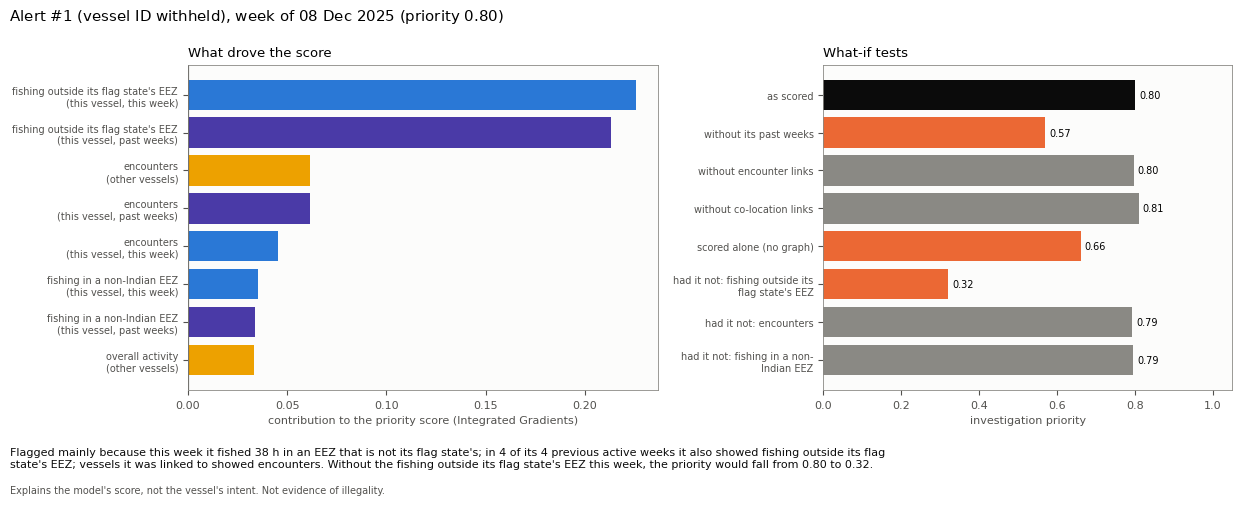

,removed,priority,delta
0,past week 2025-11-03,0.800,-0.000
1,past week 2025-11-10,0.789,-0.011
2,past week 2025-11-17,0.788,-0.013
3,past week 2025-12-01,0.792,-0.008
4,all past weeks,0.568,-0.232


,removed,priority,delta
0,all temporal edges (37),0.548,-0.253
1,all encounter edges (52),0.796,-0.004
2,all co-location edges (190),0.809,0.009
3,single most influential co-location edge (from vessel_########),0.807,0.007
4,every edge (vessel scored alone),0.660,-0.140


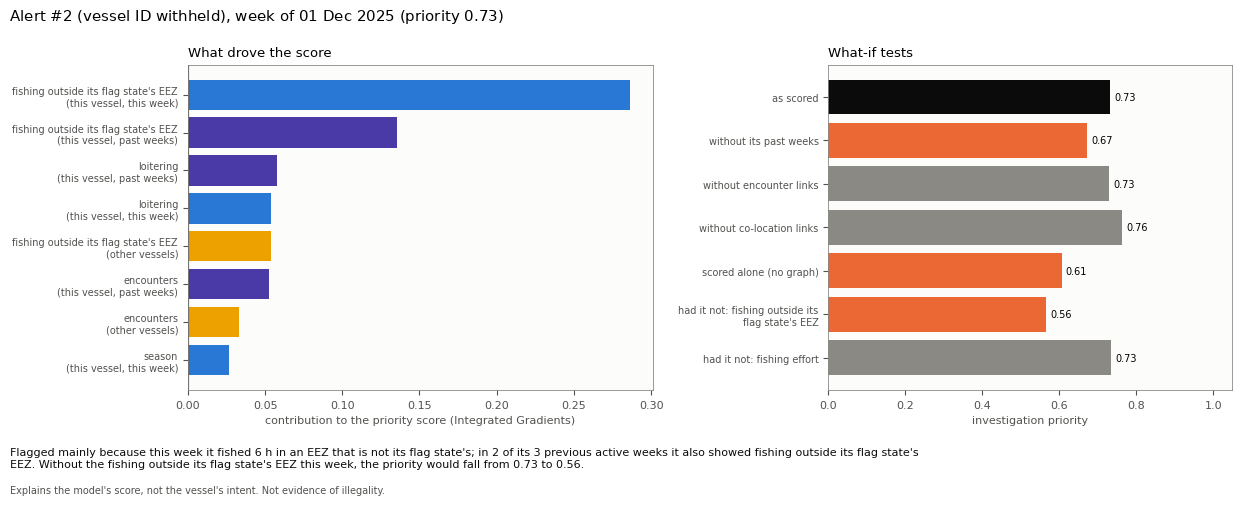

,removed,priority,delta
0,past week 2025-10-06,0.674,-0.059
1,past week 2025-10-20,0.746,0.014
2,past week 2025-10-27,0.722,-0.011
3,all past weeks,0.671,-0.061


,removed,priority,delta
0,all temporal edges (7),0.668,-0.064
1,all encounter edges (4),0.729,-0.003
2,all co-location edges (78),0.763,0.030
3,single most influential co-location edge (from vessel_########),0.746,0.013
4,every edge (vessel scored alone),0.606,-0.127


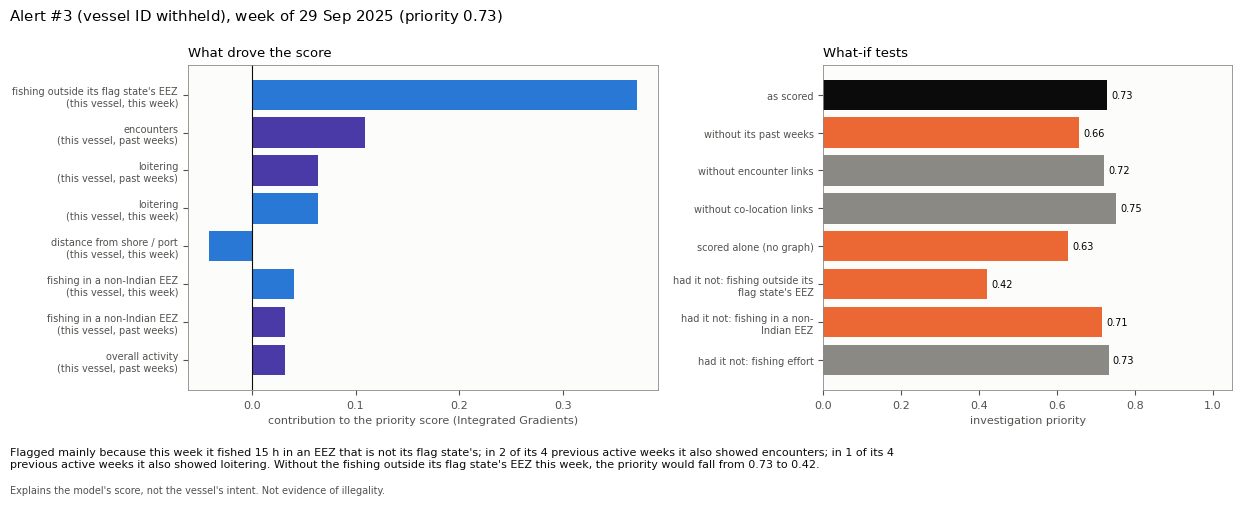

,removed,priority,delta
0,past week 2025-06-16,0.738,0.011
1,past week 2025-07-21,0.719,-0.008
2,past week 2025-08-04,0.669,-0.059
3,past week 2025-09-08,0.713,-0.015
4,all past weeks,0.655,-0.072


,removed,priority,delta
0,all temporal edges (7),0.655,-0.072
1,all encounter edges (12),0.721,-0.007
2,all co-location edges (62),0.752,0.024
3,single most influential co-location edge (from vessel_########),0.741,0.014
4,every edge (vessel scored alone),0.628,-0.099


In [7]:
for a, c in list(zip(alerts.itertuples(), cards))[:N_FIGURES]:
    fig = viz.plot_alert_explanation(c, f"Alert #{a.rank}: {a.vessel_id}, week of {a.week:%d %b %Y} (priority {c['priority']:.2f})",
                                     FIG / f"m4_alert_{a.rank:02d}.png")
    plt.show()
    display(c["temporal"].round(3)); display(c["edges"].round(3))

## 5 · Global view: which information do the models rely on?

,Temporal GAT (full graph),Gradient boosting
group,,
fishing outside its flag state's EEZ,0.0627,0.0850
loitering,0.0360,0.0329
encounters,0.0215,0.0158
location,0.0196,0.0996
distance from shore / port,0.0121,0.0469
fishing inside a protected area,0.0098,0.0019
season,0.0075,0.0279
fishing in a non-Indian EEZ,0.0060,0.0140
overall activity,0.0049,-0.0012


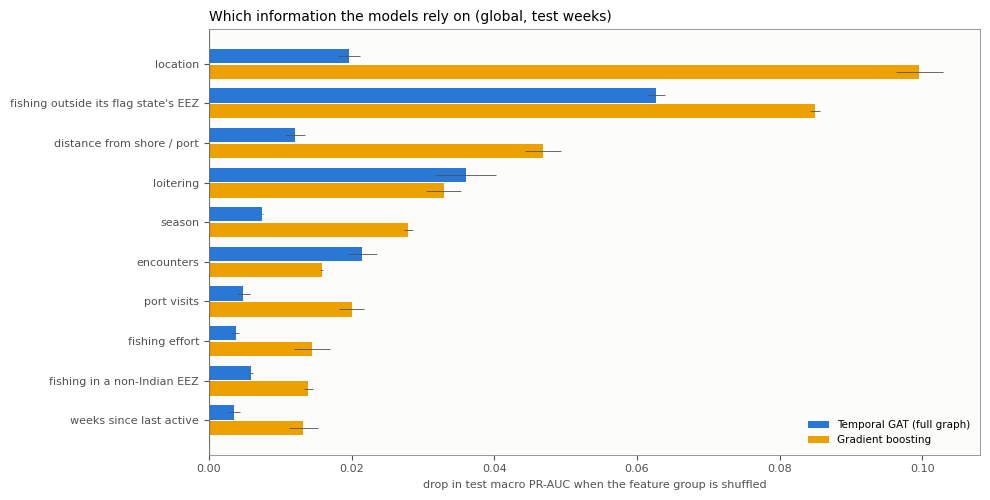

In [8]:
X_raw = G["X_raw"].values.astype(np.float32)
mu, sd = np.asarray(stats["mean"]), np.asarray(stats["sd"])
g_all = {k: torch.as_tensor(v, device=DEVICE) for k, v in (("ei", G["edge_index"]), ("ea", G["edge_attr"]), ("lag", G["edge_lag"]))}

def predict_gnn(Xr):
    x = torch.as_tensor(np.clip((Xr - mu) / sd, -10, 10).astype(np.float32), device=DEVICE)
    with torch.no_grad():
        return torch.sigmoid(R["model"](x, g_all["ei"], g_all["ea"], g_all["lag"])).cpu().numpy()

def predict_hgb(Xr):
    return np.column_stack([hgb[t].predict_proba(Xr)[:, 1] for t in tasks])

test_rows = split == "test"
imp = {"Temporal GAT (full graph)": xp.group_permutation_importance(predict_gnn, G, test_rows, tasks, X_raw, repeats=3),
       "Gradient boosting": xp.group_permutation_importance(predict_hgb, G, test_rows, tasks, X_raw, repeats=3)}
for k, v in imp.items():
    v.to_csv(OUT / f"m4_global_importance_{k.split()[0].lower()}.csv", index=False)
display(pd.concat({k: v.set_index("group").importance for k, v in imp.items()}, axis=1).round(4))
fig = viz.plot_global_importance(imp, FIG / "m4_global_importance.png"); plt.show()

## 6 · Can the explanations be trusted?

- **Completeness error:** how far the attributions are from adding up to (score − baseline score). It should be close to 0.
- **Deletion fidelity:** the score drop after removing the top-5 attributed inputs, compared with 5 random inputs.
- **Sparsity:** the share of inputs needed to cover 80% of the attribution. Lower means a simpler explanation.
- **Stability:** the same alerts are explained by the models trained with the other seeds; this is the Spearman correlation of the attributions.

,rank,priority,completeness_error,drop_top_k,drop_random_k,sparsity_80pct,stability
0,1,0.8002,0.0049,0.5827,0.0002,0.0281,0.1772
1,2,0.7326,0.0005,0.3039,0.0003,0.0610,0.5400
2,3,0.7278,0.0033,0.3705,0.0007,0.0557,0.3237
3,4,0.7207,0.0003,0.5670,0.0010,0.0478,0.5389
4,5,0.7124,0.0041,0.5795,0.0160,0.0543,0.1956
5,6,0.7124,0.0006,0.5503,-0.0003,0.0401,0.4201
6,7,0.5762,0.0001,0.3401,0.0080,0.1707,0.1546
7,8,0.7081,0.0001,0.6325,0.0004,0.0449,0.5154
8,9,0.7072,0.0009,0.2363,0.0003,0.0610,0.4932
9,10,0.7017,0.0009,0.4696,0.0126,0.0507,0.4841


,priority,completeness_error,drop_top_k,drop_random_k,sparsity_80pct,stability
mean,0.6882,0.0011,0.421,0.0058,0.0691,0.444
median,0.6949,0.0005,0.387,0.0033,0.0610,0.478


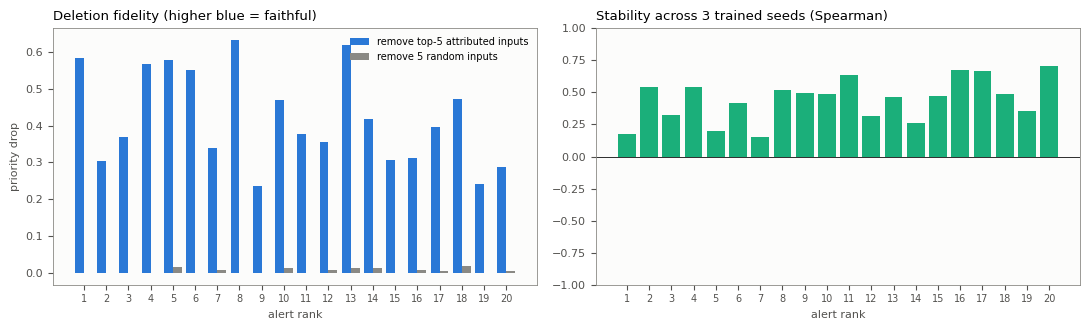

In [9]:
other = [s for s in CFG.seeds if s != best_seed]
stab = []
if other:
    others = {s: make_explainer(models[s]) for s in other}
    for n, c in zip(alert_nodes, cards):
        tabs = [c["attribution"]]
        for s, e in others.items():
            sg = e.subgraph(n)
            tabs.append(e.attribution_table(sg, e.integrated_gradients(sg)))
        stab.append(xp.seed_stability(tabs))
else:
    stab = [np.nan] * len(cards)
quality = pd.DataFrame({"rank": alerts["rank"], "priority": [c["priority"] for c in cards],
                        "completeness_error": [c["completeness_error"] for c in cards],
                        "drop_top_k": [c["fidelity"]["drop_top_k"] for c in cards],
                        "drop_random_k": [c["fidelity"]["drop_random_k"] for c in cards],
                        "sparsity_80pct": [c["sparsity_80pct"] for c in cards], "stability": stab})
quality.to_csv(OUT / "m4_explanation_quality.csv", index=False)
display(quality.round(4))
display(quality.drop(columns="rank").agg(["mean", "median"]).round(4))
fig = viz.plot_explanation_quality(quality, FIG / "m4_explanation_quality.png"); plt.show()

## 7 · Save the alert cards (JSON) and summary

In [10]:
import shutil
from src.config import FIGURE_DIR, METRIC_DIR
js = [xp.card_to_json(c, nodes, a._asdict()) for a, c in zip(alerts.itertuples(index=False), cards)]
xp.save_cards(js, OUT / "m4_alert_cards.json",
              {"model": "Temporal GAT (full graph)", "seed": int(best_seed), "split": "time",
               "period": f"test weeks from {CFG.test_start}", "method": "Integrated Gradients + exact temporal/edge "
               "occlusion + counterfactuals", "priority_weights": CFG.priority_weights})
print(json.dumps(js[0], indent=2, default=str)[:2500])
m4 = {"n_alerts": len(cards), "best_seed": int(best_seed),
      "quality_mean": quality.drop(columns="rank").mean().round(4).to_dict(),
      "top_global_groups": {k: v.head(5).group.tolist() for k, v in imp.items()},
      "caveat": rm.REAL_MODEL_CAVEAT}
(OUT / "m4_summary.json").write_text(json.dumps(m4, indent=2, default=str))
for p in (FIGURE_DIR, METRIC_DIR):
    p.mkdir(parents=True, exist_ok=True)
for f in FIG.glob("m4_*.png"):
    shutil.copy(f, FIGURE_DIR / f.name)
for f in OUT.glob("m4_*.*"):
    shutil.copy(f, METRIC_DIR / f.name)
print("saved:", *sorted(p.name for p in OUT.glob("m4_*")), sep="\n  ")

{
  "vessel_id": "vessel_########",
  "vessel_class": "fishing",
  "week": "2025-12-08",
  "approx_position": [
    6.0,
    80.7
  ],
  "investigation_priority": 0.8,
  "forecast_next_week": {
    "encounter": 0.1754,
    "loitering": 0.2716,
    "fishing_in_mpa": 0.0113,
    "fishing_outside_flag_eez": 0.7775
  },
  "reason": "Flagged mainly because this week it fished 38 h in an EEZ that is not its flag state's; in 4 of its 4 previous active weeks it also showed fishing outside its flag state's EEZ; vessels it was linked to showed encounters. Without the fishing outside its flag state's EEZ this week, the priority would fall from 0.80 to 0.32.",
  "top_contributions": [
    {
      "role": "this vessel, this week",
      "group": "fishing outside its flag state's EEZ",
      "contribution": 0.2258
    },
    {
      "role": "this vessel, past weeks",
      "group": "fishing outside its flag state's EEZ",
      "contribution": 0.213
    },
    {
      "role": "other vessels",
      "

## How to read this

- **Top driver: "this vessel, this week".** The alert rests on what the vessel just did, which is the most transparent kind of alert.
- **History effect.** A large drop when its past weeks are removed means the score rests on a *repeated* pattern. That is stronger grounds for a look than a single week.
- **Other-vessel effect.** The effect of encounter and co-location links. Near zero matches 04b's finding that neighbours add little on this data.
- **Counterfactual.** The single behaviour that, had it not happened, would lower the priority the most. This is the most useful line for an analyst.
- **Quality checks.** Completeness close to 0, a top-5 deletion drop far above the random drop, and stability close to 1 mean the explanation reflects what the model actually does.

**Limits**
- Explanations describe the model, not reality or intent.
- A foreign-flag vessel may be fishing legally under an access agreement or licence.
- Protected-area boundaries come from GFW's MPA layer and may include zones where fishing is allowed.
- Every alert needs human verification before any action.

Attribution: data from **Global Fishing Watch**, non-commercial use.